# 12. Advanced Deep Learning with PyTorch: Attention, Transformers, and Vision Transformers

A practical, self-contained learning notebook. We move from attention mathematics to Transformer components, sequence modeling, and a small Vision Transformer.

**Learning objectives**
- Understand Query, Key, and Value.
- Derive and implement scaled dot-product attention.
- Work with masks, multi-head attention, and positional encoding.
- Build encoder and decoder blocks.
- Convert images into patch sequences and implement a Mini ViT.
- Train and evaluate models using synthetic data.

**No external dataset is required.** All data is generated locally. Synthetic tasks demonstrate implementation mechanics, not real-world generalization.

Requirements: Python 3.9+, PyTorch, NumPy, and Matplotlib.

## 0. Setup and reproducibility

We set random seeds and select CPU or CUDA automatically.

In [1]:
import math, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", device)

PyTorch: 2.5.1+cu121 | Device: cuda


## 1. Why attention?

Sequences occur in text, biological measurements, time series, and image patches. The meaning of one element may depend on distant elements. Recurrent networks process sequences step by step, while convolutions aggregate information through local receptive fields. Attention offers content-dependent communication: each position can assign weights to other positions and combine their information.

For a sequence of length $L$, dense self-attention forms an $L\times L$ matrix. This enables long-range interactions but has quadratic sequence-length cost.

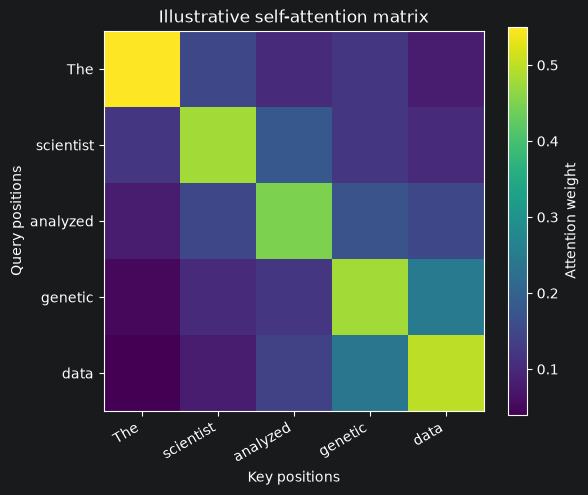

In [2]:
# Illustrative attention weights (not learned by a model).
tokens = ["The", "scientist", "analyzed", "genetic", "data"]
weights = torch.tensor([
    [0.55, 0.15, 0.10, 0.12, 0.08],
    [0.12, 0.48, 0.18, 0.12, 0.10],
    [0.08, 0.15, 0.45, 0.17, 0.15],
    [0.05, 0.10, 0.12, 0.48, 0.25],
    [0.04, 0.08, 0.14, 0.24, 0.50],
])
plt.figure(figsize=(6, 5))
plt.imshow(weights, cmap="viridis")
plt.xticks(range(len(tokens)), tokens, rotation=30, ha="right")
plt.yticks(range(len(tokens)), tokens)
plt.colorbar(label="Attention weight")
plt.title("Illustrative self-attention matrix")
plt.xlabel("Key positions"); plt.ylabel("Query positions")
plt.tight_layout(); plt.show()

### 1.1 Types of attention

- **Self-attention:** Q, K, and V come from the same sequence.
- **Cross-attention:** Q comes from one sequence; K and V come from another.
- **Causal self-attention:** position $i$ can use only positions $j\leq i$, preventing access to future tokens.

Attention is not universally superior. Its dense score computation is approximately $O(L^2d)$ for sequence length $L$ and feature dimension $d$.

## 2. Query, Key, and Value

Let the input be $X\in\mathbb{R}^{B\times L\times d_{model}}$, where $B$ is batch size and $L$ is sequence length. Learned projections produce:

$$Q=XW_Q,\qquad K=XW_K,\qquad V=XW_V.$$

- **Query:** what information is this position looking for?
- **Key:** what information does this position advertise?
- **Value:** what information will this position contribute?

Dot products compare queries with keys; softmax turns scores into normalized weights.

In [3]:
B, L, d_model = 2, 5, 16
X = torch.randn(B, L, d_model)
W_Q = nn.Linear(d_model, d_model, bias=False)
W_K = nn.Linear(d_model, d_model, bias=False)
W_V = nn.Linear(d_model, d_model, bias=False)
Q, K_, V = W_Q(X), W_K(X), W_V(X)
print("X, Q, K, V:", X.shape, Q.shape, K_.shape, V.shape)

X, Q, K, V: torch.Size([2, 5, 16]) torch.Size([2, 5, 16]) torch.Size([2, 5, 16]) torch.Size([2, 5, 16])


## 3. Scaled dot-product attention from scratch

$$
Attention(Q,K,V)=softmax\left(\frac{QK^T}{\sqrt{d_k}}+M\right)V
$$

$M$ is an optional additive mask. Dividing by $\sqrt{d_k}$ controls the scale of dot-product logits. Without scaling, large dimensions can produce very large logits, making softmax overly peaked and gradients less useful.

Shapes: Q = $(B,L_q,d_k)$, K = $(B,L_k,d_k)$, V = $(B,L_k,d_v)$. The output is $(B,L_q,d_v)$.

Output: torch.Size([2, 3, 6]) | Attention: torch.Size([2, 3, 5])
Attention row sums: tensor([[1.0000, 1.0000, 1.0000],
        [1.0000, 1.0000, 1.0000]])


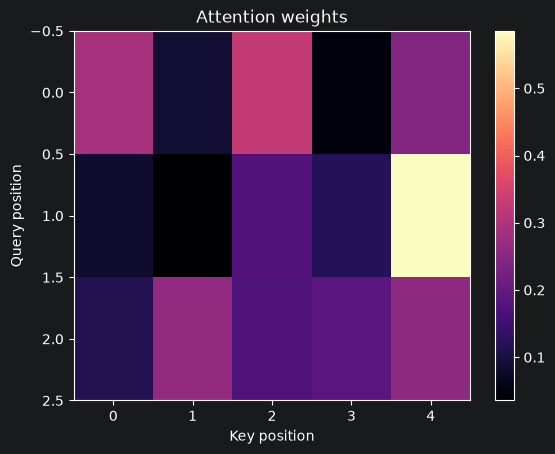

In [4]:
def scaled_dot_product_attention(query, key, value, mask=None, dropout_p=0.0, training=False):
    # Compute pairwise query-key similarity and scale it.
    scores = query @ key.transpose(-2, -1)
    scores = scores / math.sqrt(query.size(-1))

    # Boolean mask convention: True = allowed, False = blocked.
    if mask is not None:
        scores = scores.masked_fill(~mask, torch.finfo(scores.dtype).min)

    # Normalize over key positions.
    attention = torch.softmax(scores, dim=-1)
    attention = F.dropout(attention, p=dropout_p, training=training)
    output = attention @ value
    return output, attention

q = torch.randn(2, 3, 8)
k = torch.randn(2, 5, 8)
v = torch.randn(2, 5, 6)
out, attn = scaled_dot_product_attention(q, k, v)
print("Output:", out.shape, "| Attention:", attn.shape)
print("Attention row sums:", attn.sum(-1))
plt.imshow(attn[0].detach(), cmap="magma", aspect="auto")
plt.colorbar(); plt.xlabel("Key position"); plt.ylabel("Query position")
plt.title("Attention weights"); plt.show()

### 3.1 Causal masking

A causal mask is lower triangular. It allows each token to attend to itself and earlier tokens, but not future tokens.

In [6]:
# Create a causal mask
def causal_mask(length, device=None):
    """
    Create a lower-triangular Boolean mask for causal attention.

    True  = The position is allowed to attend.
    False = The position is blocked.
    """
    return torch.tril(
        torch.ones(length, length, dtype=torch.bool, device=device)
    )


# Define the sequence length
L = 6

# Create the causal mask on the same device as the input tensors
mask = causal_mask(L, device=device)

# Create Query, Key, and Value tensors
q = torch.randn(1, L, 8, device=device)
k = torch.randn(1, L, 8, device=device)
v = torch.randn(1, L, 8, device=device)

# Apply scaled dot-product attention with the causal mask
causal_out, causal_attn = scaled_dot_product_attention(
    q, k, v, mask=mask
)

# Display the causal mask
print("Causal Mask:")
print(mask.int())

# Display the attention weights
print("\nCausal Attention Weights:")
print(causal_attn[0])

# Verify that future-position attention weights are zero
print("\nFuture-position weights (should be zero):")
print(torch.triu(causal_attn[0], diagonal=1))

# Verify output shape and device
print("\nOutput shape:", causal_out.shape)
print("Output device:", causal_out.device)
print("Mask device:", mask.device)

Causal Mask:
tensor([[1, 0, 0, 0, 0, 0],
        [1, 1, 0, 0, 0, 0],
        [1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1]], device='cuda:0', dtype=torch.int32)

Causal Attention Weights:
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1447, 0.8553, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3392, 0.2777, 0.3830, 0.0000, 0.0000, 0.0000],
        [0.2465, 0.4377, 0.1241, 0.1916, 0.0000, 0.0000],
        [0.0684, 0.1465, 0.5446, 0.1126, 0.1280, 0.0000],
        [0.1812, 0.2538, 0.0773, 0.1137, 0.1479, 0.2261]], device='cuda:0')

Future-position weights (should be zero):
tensor([[0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0.]], device='cuda:0')

Output shape: torch.Size([1, 6, 8])
Output device: cuda:0
Mask device: cuda:0


## 4. Multi-head attention

Multiple heads perform attention in parallel, potentially learning different relationship patterns. For $h$ heads, the per-head dimension is commonly $d_k=d_{model}/h$. The concatenated heads are projected:

$$MultiHead(Q,K,V)=Concat(head_1,\ldots,head_h)W^O.$$

Therefore, $d_{model}$ must be divisible by the number of heads.

In [7]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.0):
        super().__init__()
        if d_model % num_heads:
            raise ValueError("d_model must be divisible by num_heads")
        self.d_model, self.num_heads = d_model, num_heads
        self.head_dim = d_model // num_heads
        self.q = nn.Linear(d_model, d_model)
        self.k = nn.Linear(d_model, d_model)
        self.v = nn.Linear(d_model, d_model)
        self.out = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def split(self, x):
        B, L, _ = x.shape
        return x.view(B, L, self.num_heads, self.head_dim).transpose(1, 2)

    def forward(self, query, key, value, mask=None, return_attention=False):
        Q, K, V = self.split(self.q(query)), self.split(self.k(key)), self.split(self.v(value))
        scores = (Q @ K.transpose(-2, -1)) / math.sqrt(self.head_dim)
        if mask is not None:
            if mask.dim() == 2: mask = mask[None, None, :, :]
            elif mask.dim() == 3: mask = mask[:, None, :, :]
            scores = scores.masked_fill(~mask, torch.finfo(scores.dtype).min)
        attn = self.dropout(torch.softmax(scores, dim=-1))
        context = attn @ V
        context = context.transpose(1, 2).contiguous()
        B, L, _, _ = context.shape
        context = context.view(B, L, self.d_model)
        result = self.out(context)
        return (result, attn) if return_attention else result

mha = MultiHeadAttention(32, 4, dropout=0.1).to(device)
sample = torch.randn(2, 7, 32, device=device)
result, head_weights = mha(sample, sample, sample, return_attention=True)
print(result.shape, head_weights.shape)  # (B,L,d_model), (B,heads,L,L)

torch.Size([2, 7, 32]) torch.Size([2, 4, 7, 7])


## 5. Positional encoding

Self-attention does not inherently know token order. Positional information is added to token embeddings. Sinusoidal encodings use:

$$PE(pos,2i)=\sin\left(pos/10000^{2i/d_{model}}\right)$$
$$PE(pos,2i+1)=\cos\left(pos/10000^{2i/d_{model}}\right).$$

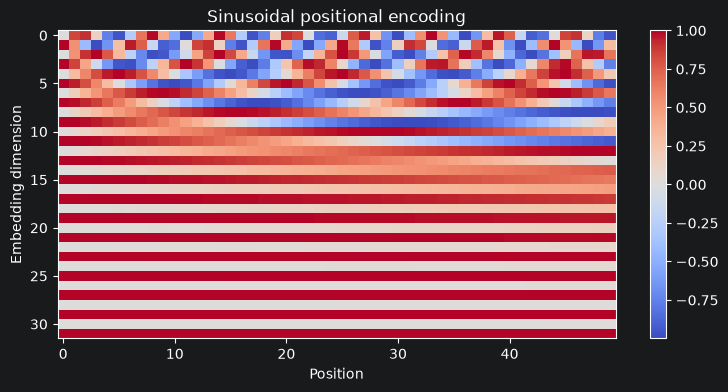

In [8]:
class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model, max_length=5000):
        super().__init__()
        pos = torch.arange(max_length).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_length, d_model)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div[:pe[:, 1::2].shape[1]])
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

pos = SinusoidalPositionalEncoding(32, 100)
plt.figure(figsize=(9, 4))
plt.imshow(pos.pe[0, :50].T, aspect="auto", cmap="coolwarm")
plt.xlabel("Position"); plt.ylabel("Embedding dimension")
plt.title("Sinusoidal positional encoding"); plt.colorbar(); plt.show()

## 6. Transformer encoder

A standard encoder layer contains multi-head self-attention and a position-wise feed-forward network. Residual connections and layer normalization stabilize optimization.

$$X_1=LayerNorm(X+MHA(X))$$
$$Y=LayerNorm(X_1+FFN(X_1))$$

The feed-forward network is applied independently at every sequence position:
$FFN(x)=W_2\,GELU(W_1x+b_1)+b_2$.

In [9]:
class TransformerEncoderLayer(nn.Module):
    def __init__(self, d_model, heads, ff_dim, dropout=0.1):
        super().__init__()
        self.attn = MultiHeadAttention(d_model, heads, dropout)
        self.ffn = nn.Sequential(nn.Linear(d_model, ff_dim), nn.GELU(),
                                  nn.Dropout(dropout), nn.Linear(ff_dim, d_model))
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        x = self.norm1(x + self.drop(self.attn(x, x, x, mask)))
        x = self.norm2(x + self.drop(self.ffn(x)))
        return x

class TransformerEncoder(nn.Module):
    def __init__(self, d_model, heads, ff_dim, layers):
        super().__init__()
        self.layers = nn.ModuleList([
            TransformerEncoderLayer(d_model, heads, ff_dim) for _ in range(layers)
        ])
    def forward(self, x, mask=None):
        for layer in self.layers:
            x = layer(x, mask)
        return x

encoder = TransformerEncoder(32, 4, 64, 2).to(device)
encoded = encoder(torch.randn(3, 10, 32, device=device))
print("Encoder output:", encoded.shape)

Encoder output: torch.Size([3, 10, 32])


## 7. Transformer decoder and cross-attention

A decoder layer combines masked target self-attention, cross-attention over encoder outputs, and a feed-forward network. Cross-attention uses target states as queries and encoder memory as keys and values.

In [10]:
class TransformerDecoderLayer(nn.Module):
    def __init__(self, d_model, heads, ff_dim, dropout=0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, heads, dropout)
        self.cross_attn = MultiHeadAttention(d_model, heads, dropout)
        self.ffn = nn.Sequential(nn.Linear(d_model, ff_dim), nn.GELU(),
                                  nn.Dropout(dropout), nn.Linear(ff_dim, d_model))
        self.norms = nn.ModuleList([nn.LayerNorm(d_model) for _ in range(3)])
        self.drop = nn.Dropout(dropout)

    def forward(self, target, memory, causal=None, memory_mask=None):
        z = self.self_attn(target, target, target, causal)
        target = self.norms[0](target + self.drop(z))
        z = self.cross_attn(target, memory, memory, memory_mask)
        target = self.norms[1](target + self.drop(z))
        target = self.norms[2](target + self.drop(self.ffn(target)))
        return target

decoder = TransformerDecoderLayer(32, 4, 64).to(device)
tgt = torch.randn(2, 6, 32, device=device)
memory = torch.randn(2, 9, 32, device=device)
decoded = decoder(tgt, memory, causal=causal_mask(6, device=device))
print("Decoder output:", decoded.shape)

Decoder output: torch.Size([2, 6, 32])


## 8. Sequence classification with PyTorch Transformer layers

We now use PyTorch's optimized `nn.TransformerEncoderLayer`. The synthetic classification task labels a sequence according to whether the mean of feature 0 is positive. This gives us a fast, reproducible training exercise without external files.

In [11]:
def make_sequence_data(n=1200, length=12, features=8):
    x = torch.randn(n, length, features)
    y = (x[:, :, 0].mean(dim=1) > 0).long()
    return x, y

X, y = make_sequence_data()
cut = int(0.8 * len(X))
train_loader = DataLoader(TensorDataset(X[:cut], y[:cut]), batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(X[cut:], y[cut:]), batch_size=128)

class SequenceClassifier(nn.Module):
    def __init__(self, input_dim=8, d_model=32, heads=4, layers=2):
        super().__init__()
        self.proj = nn.Linear(input_dim, d_model)
        self.pos = SinusoidalPositionalEncoding(d_model, 64)
        layer = nn.TransformerEncoderLayer(
            d_model, heads, 64, batch_first=True, activation="gelu"
        )
        self.encoder = nn.TransformerEncoder(layer, layers)
        self.head = nn.Sequential(nn.LayerNorm(d_model), nn.Linear(d_model, 2))

    def forward(self, x):
        x = self.pos(self.proj(x))
        x = self.encoder(x)
        return self.head(x.mean(dim=1))

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum = correct = count = 0
    for bx, by in loader:
        bx, by = bx.to(device), by.to(device)
        if training: optimizer.zero_grad()
        with torch.set_grad_enabled(training):
            logits = model(bx)
            loss = F.cross_entropy(logits, by)
            if training:
                loss.backward()
                optimizer.step()
        loss_sum += loss.item() * len(by)
        correct += (logits.argmax(1) == by).sum().item()
        count += len(by)
    return loss_sum / count, correct / count

seq_model = SequenceClassifier().to(device)
opt = torch.optim.AdamW(seq_model.parameters(), lr=1e-3)
seq_hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
for epoch in range(8):
    tr_l, tr_a = run_epoch(seq_model, train_loader, opt)
    va_l, va_a = run_epoch(seq_model, val_loader)
    for key, value in zip(seq_hist, [tr_l, va_l, tr_a, va_a]):
        seq_hist[key].append(value)
    print(f"Epoch {epoch+1}: train acc={tr_a:.3f}, val acc={va_a:.3f}")

Epoch 1: train acc=0.561, val acc=0.700
Epoch 2: train acc=0.749, val acc=0.842
Epoch 3: train acc=0.857, val acc=0.921
Epoch 4: train acc=0.947, val acc=0.954
Epoch 5: train acc=0.964, val acc=0.971
Epoch 6: train acc=0.961, val acc=0.958
Epoch 7: train acc=0.969, val acc=0.983
Epoch 8: train acc=0.977, val acc=0.983


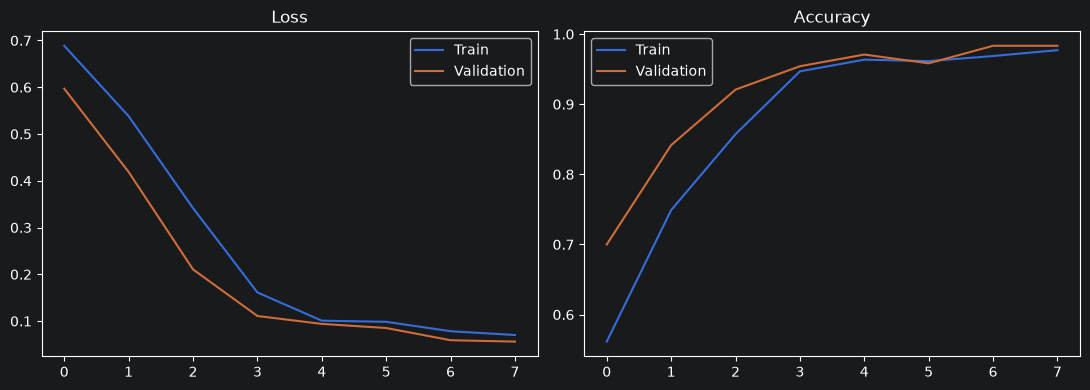

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(seq_hist["train_loss"], label="Train")
ax[0].plot(seq_hist["val_loss"], label="Validation")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(seq_hist["train_acc"], label="Train")
ax[1].plot(seq_hist["val_acc"], label="Validation")
ax[1].set_title("Accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

## 9. Vision Transformer: images become sequences

For an image of shape $(C,H,W)$, split it into non-overlapping patches of size $P\times P$. The number of patches is:

$$N=(H/P)(W/P).$$

Each flattened patch is projected into an embedding. A class token can be prepended, and positional embeddings encode spatial order. For a $32\times32$ image with $8\times8$ patches, there are 16 patch tokens.

In [13]:
def image_to_patches(images, patch_size):
    B, C, H, W = images.shape
    if H % patch_size or W % patch_size:
        raise ValueError("Image dimensions must be divisible by patch_size")
    patches = images.unfold(2, patch_size, patch_size).unfold(3, patch_size, patch_size)
    patches = patches.permute(0, 2, 3, 1, 4, 5).contiguous()
    return patches.view(B, -1, C * patch_size * patch_size)

toy_images = torch.randn(2, 3, 32, 32)
patches = image_to_patches(toy_images, 8)
print("Image:", toy_images.shape, "Patches:", patches.shape)

Image: torch.Size([2, 3, 32, 32]) Patches: torch.Size([2, 16, 192])


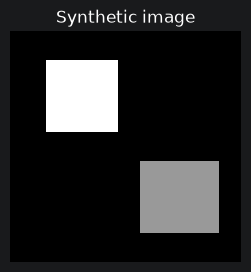

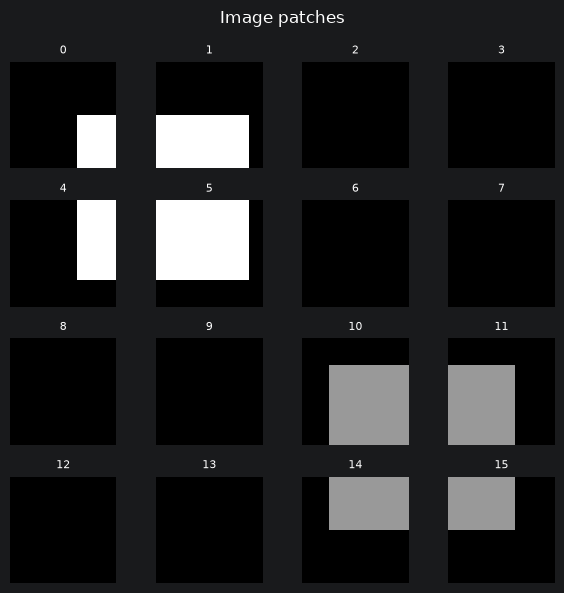

In [14]:
# Display a generated image and its 8x8 patches.
toy = torch.zeros(1, 32, 32)
toy[:, 4:14, 5:15] = 1
toy[:, 18:28, 18:29] = 0.6
plt.figure(figsize=(3, 3)); plt.imshow(toy[0], cmap="gray"); plt.title("Synthetic image"); plt.axis("off"); plt.show()

grid = toy.unfold(1, 8, 8).unfold(2, 8, 8)[0]
fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for i in range(4):
    for j in range(4):
        axes[i, j].imshow(grid[i, j], cmap="gray", vmin=0, vmax=1)
        axes[i, j].set_title(str(i*4+j), fontsize=8)
        axes[i, j].axis("off")
plt.suptitle("Image patches"); plt.tight_layout(); plt.show()

## 10. Implementing a Mini Vision Transformer

The architecture consists of patch embedding, a learnable class token, learnable positional embeddings, Transformer encoder layers, and a classification head. This compact model is designed for education, not state-of-the-art performance.

In [16]:
class MiniViT(nn.Module):
    def __init__(self, image_size=32, patch_size=8, channels=1, classes=2,
                 d_model=64, heads=4, layers=2, mlp_dim=128, dropout=0.1):
        super().__init__()
        if image_size % patch_size:
            raise ValueError("image_size must be divisible by patch_size")
        n_patches = (image_size // patch_size) ** 2
        patch_dim = channels * patch_size * patch_size
        self.patch_size = patch_size
        self.patch_proj = nn.Linear(patch_dim, d_model)
        self.cls = nn.Parameter(torch.zeros(1, 1, d_model))
        self.pos = nn.Parameter(torch.randn(1, n_patches + 1, d_model) * 0.02)
        self.drop = nn.Dropout(dropout)
        layer = nn.TransformerEncoderLayer(
            d_model, heads, mlp_dim, dropout, batch_first=True,
            activation="gelu", norm_first=True
        )
        self.encoder = nn.TransformerEncoder(layer, layers)
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, classes)

    def forward(self, images):
        x = self.patch_proj(image_to_patches(images, self.patch_size))
        cls = self.cls.expand(x.size(0), -1, -1)
        x = torch.cat([cls, x], dim=1)
        x = self.drop(x + self.pos[:, :x.size(1)])
        x = self.encoder(x)
        return self.head(self.norm(x[:, 0]))

vit = MiniViT().to(device)
print("Logit shape:", vit(torch.randn(4, 1, 32, 32, device=device)).shape)
print("Trainable parameters:", sum(p.numel() for p in vit.parameters() if p.requires_grad))

Logit shape: torch.Size([4, 2])
Trainable parameters: 72514


## 11. Train the Mini ViT on synthetic images

We generate two classes: a bright square on the left or on the right. Random vertical position and low-amplitude noise make the examples less identical. The dataset is generated locally and does not require a download.

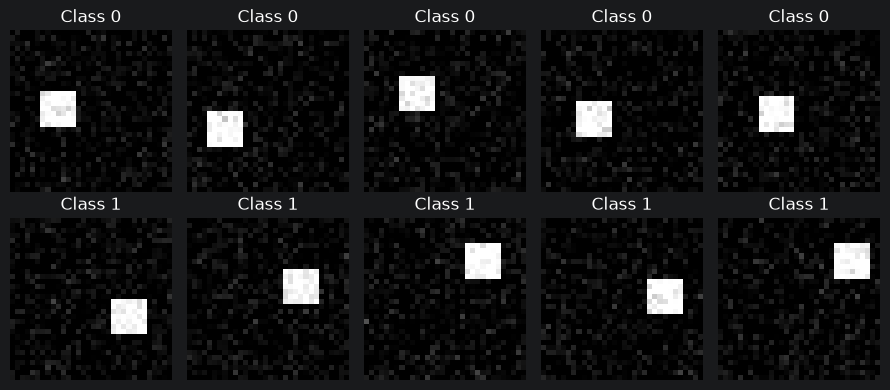

In [17]:
def make_synthetic_images(n=1000, size=32):
    images = torch.zeros(n, 1, size, size)
    labels = torch.randint(0, 2, (n,))
    for i in range(n):
        top = random.randint(5, 17)
        left = random.randint(3, 8) if labels[i].item() == 0 else random.randint(19, 24)
        images[i, 0, top:top+7, left:left+7] = 1.0
    images.add_(0.08 * torch.randn_like(images)).clamp_(0, 1)
    return images, labels

X_img, y_img = make_synthetic_images()
perm = torch.randperm(len(X_img))
X_img, y_img = X_img[perm], y_img[perm]
cut = int(0.8 * len(X_img))
train_img_loader = DataLoader(TensorDataset(X_img[:cut], y_img[:cut]), batch_size=64, shuffle=True)
val_img_loader = DataLoader(TensorDataset(X_img[cut:], y_img[cut:]), batch_size=128)

fig, axes = plt.subplots(2, 5, figsize=(9, 4))
for cls in (0, 1):
    ids = torch.where(y_img == cls)[0][:5]
    for j, idx in enumerate(ids):
        axes[cls, j].imshow(X_img[idx, 0], cmap="gray", vmin=0, vmax=1)
        axes[cls, j].set_title(f"Class {cls}"); axes[cls, j].axis("off")
plt.tight_layout(); plt.show()

In [18]:
vit_model = MiniViT().to(device)
vit_opt = torch.optim.AdamW(vit_model.parameters(), lr=1e-3, weight_decay=1e-4)
vit_hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

for epoch in range(8):
    tr_l, tr_a = run_epoch(vit_model, train_img_loader, vit_opt)
    va_l, va_a = run_epoch(vit_model, val_img_loader)
    for key, value in zip(vit_hist, [tr_l, va_l, tr_a, va_a]):
        vit_hist[key].append(value)
    print(f"Epoch {epoch+1}: train acc={tr_a:.3f}, val acc={va_a:.3f}")

Epoch 1: train acc=0.511, val acc=0.485
Epoch 2: train acc=0.501, val acc=0.515
Epoch 3: train acc=0.589, val acc=0.765
Epoch 4: train acc=0.734, val acc=0.820
Epoch 5: train acc=0.940, val acc=1.000
Epoch 6: train acc=0.975, val acc=0.995
Epoch 7: train acc=0.991, val acc=1.000
Epoch 8: train acc=0.993, val acc=1.000


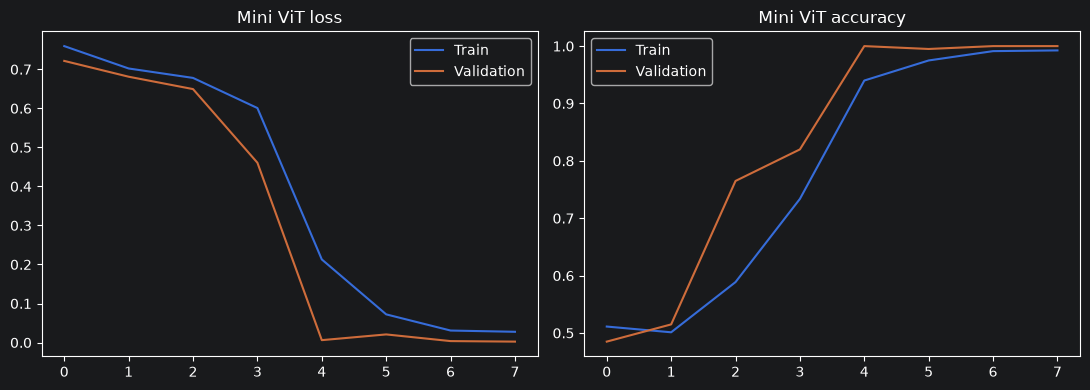

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(vit_hist["train_loss"], label="Train")
ax[0].plot(vit_hist["val_loss"], label="Validation")
ax[0].set_title("Mini ViT loss"); ax[0].legend()
ax[1].plot(vit_hist["train_acc"], label="Train")
ax[1].plot(vit_hist["val_acc"], label="Validation")
ax[1].set_title("Mini ViT accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

## 12. Experiments, saving, review, and exercises

### Suggested experiments
1. Compare patch sizes 4, 8, and 16. Smaller patches produce more tokens and a larger attention matrix.
2. Compare 1, 2, and 4 attention heads while keeping `d_model` fixed.
3. Compare one versus two encoder layers.
4. Replace learnable ViT positional embeddings with sinusoidal encodings.
5. Remove positional embeddings and observe the effect.
6. Change the synthetic image task to classify a diagonal line or a bright square in one of four corners.

### Complexity
Dense self-attention has approximately $O(L^2d)$ compute cost and $O(L^2)$ attention-matrix memory per head and sample. This becomes expensive for long sequences or high-resolution images.

### Save and reload

In [21]:
checkpoint_path = "mini_vit_checkpoint.pth"
config = dict(image_size=32, patch_size=8, channels=1, classes=2,
              d_model=64, heads=4, layers=2, mlp_dim=128)
torch.save({"model_state_dict": vit_model.state_dict(), "config": config}, checkpoint_path)

# Re-create the same architecture before loading its learned parameters.
loaded = MiniViT(**config).to(device)
checkpoint = torch.load(checkpoint_path, map_location=device)
loaded.load_state_dict(checkpoint["model_state_dict"])
loaded.eval()
with torch.no_grad():
    example_logits = loaded(X_img[:4].to(device))
print("Reloaded model output:", example_logits.shape)

Reloaded model output: torch.Size([4, 2])


C:\Users\mobin\AppData\Local\Temp\ipykernel_9228\2619394651.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_path, map_location=device)

### Exercises

1. Implement a padding mask for variable-length sequences.
2. Visualize attention weights separately for each head.
3. Implement learnable positional embeddings for a sequence classifier.
4. Compare pre-normalization and post-normalization Transformer blocks.
5. Build a tiny causal next-token prediction model using synthetic sequences.
6. Change the image classification task to distinguish horizontal and vertical bars.
7. Compare patch sizes and record token count, parameter count, runtime, and accuracy.
8. Calculate a confusion matrix, precision, recall, and F1-score.
9. Explain why synthetic-task performance is not evidence of real-world generalization.
10. Explain why ViT models often benefit from large-scale pretraining.

### Common mistakes

- Forgetting the $\sqrt{d_k}$ scaling factor.
- Applying softmax over the wrong dimension.
- Reversing the meaning of a Boolean attention mask.
- Omitting positional information.
- Choosing `d_model` not divisible by `num_heads`.
- Confusing image patches with individual pixels.
- Forgetting `model.train()` and `model.eval()`.
- Comparing experiments with different splits without noting the change.

### Quick reference

| Component | Purpose |
|---|---|
| Query, Key, Value | Request, matching descriptors, and retrieved information |
| Scaled dot-product attention | Weighted combination based on content similarity |
| Multi-head attention | Multiple attention patterns in parallel |
| Positional encoding | Inject sequence or spatial order |
| Encoder | Contextual sequence representation |
| Decoder masked attention | Prevent future-token access |
| Cross-attention | Attend from one sequence to another |
| Patch embedding | Convert image patches into token vectors |
| Class token | Global representation for classification |
| Vision Transformer | Apply Transformer encoders to image patches |

### Official documentation and papers

- PyTorch MultiheadAttention: https://pytorch.org/docs/stable/generated/torch.nn.MultiheadAttention.html
- PyTorch Transformer layers: https://pytorch.org/docs/stable/nn.html#transformer-layers
- PyTorch TransformerEncoder: https://pytorch.org/docs/stable/generated/torch.nn.TransformerEncoder.html
- PyTorch data loading: https://pytorch.org/docs/stable/data.html
- Attention Is All You Need: https://arxiv.org/abs/1706.03762
- An Image is Worth 16x16 Words: https://arxiv.org/abs/2010.11929

---

## Final perspective

This notebook progresses from attention mathematics to complete Transformer and Mini ViT training workflows. The from-scratch components clarify tensor operations; built-in PyTorch layers are generally preferable for optimized production systems. The synthetic tasks keep this notebook self-contained and fast, but real research or clinical applications require suitable datasets, leakage-safe splits, external validation, and domain-specific evaluation.